# Model Deployment Basics & Neural Networks from Scratch

**Topics covered**
1. Model deployment basics: saving / loading models with `pickle` and `joblib`
2. Perceptrons, activation functions, forward & backward propagation
3. Loss functions and optimizers (SGD, Momentum, Adam)
4. Building a neural network from scratch with NumPy

**Learning objectives**
- Save and load trained ML models using pickle and joblib
- Understand perceptrons, activations, forward and backward propagation
- Understand loss functions and how SGD and Adam train a model
- Implement forward pass, loss, backprop and weight updates using only NumPy

In [2]:
import time, os, pickle
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9})
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
np.random.seed(42)

---
# Part 1 — Model Deployment Basics (pickle & joblib)

Training a model is only half the job. To **deploy** it (use it in an API, app or batch job) we must
**serialize** it — save the trained model to disk — and **deserialize** it later without retraining.

| Tool | Best for | Notes |
|---|---|---|
| `pickle` | Any Python object | Standard library, general purpose |
| `joblib` | Objects with large NumPy arrays (sklearn models) | Faster / smaller for arrays, supports compression |

> **Security warning:** never load a pickle/joblib file from an untrusted source — loading can execute arbitrary code.
> Also, load with the *same library versions* that were used for saving.

In [3]:
# 1. Train a model
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.25,
                                                    random_state=42, stratify=data.target)
model = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
print("Test accuracy of trained model:", round(accuracy_score(y_test, model.predict(X_test)), 4))

Test accuracy of trained model: 0.958


In [4]:
# 2. Save with pickle and joblib (and joblib + compression), measuring time and size
os.makedirs("saved_models", exist_ok=True)
results = {}

def bench(name, save_fn, load_fn, path):
    t0 = time.perf_counter(); save_fn(path); t_save = time.perf_counter() - t0
    t0 = time.perf_counter(); loaded = load_fn(path);  t_load = time.perf_counter() - t0
    results[name] = dict(size=os.path.getsize(path) / 1024, save=t_save * 1000, load=t_load * 1000, model=loaded)

bench("pickle", lambda p: pickle.dump(model, open(p, "wb")), lambda p: pickle.load(open(p, "rb")),
      "saved_models/rf.pkl")
bench("joblib", lambda p: joblib.dump(model, p), joblib.load, "saved_models/rf.joblib")
bench("joblib\n(compress=3)", lambda p: joblib.dump(model, p, compress=3), joblib.load,
      "saved_models/rf_c3.joblib")

# 3. Verify that loaded models give identical predictions
for k, v in results.items():
    same = np.array_equal(v["model"].predict(X_test), model.predict(X_test))
    print(f"{k.replace(chr(10), ' '):<20} size={v['size']:9.1f} KB  save={v['save']:7.1f} ms  "
          f"load={v['load']:7.1f} ms  identical predictions: {same}")

pickle               size=    898.6 KB  save=   51.9 ms  load=   34.3 ms  identical predictions: True
joblib               size=    922.1 KB  save=  375.7 ms  load=  227.6 ms  identical predictions: True
joblib (compress=3)  size=    179.4 KB  save=  333.7 ms  load=  127.0 ms  identical predictions: True


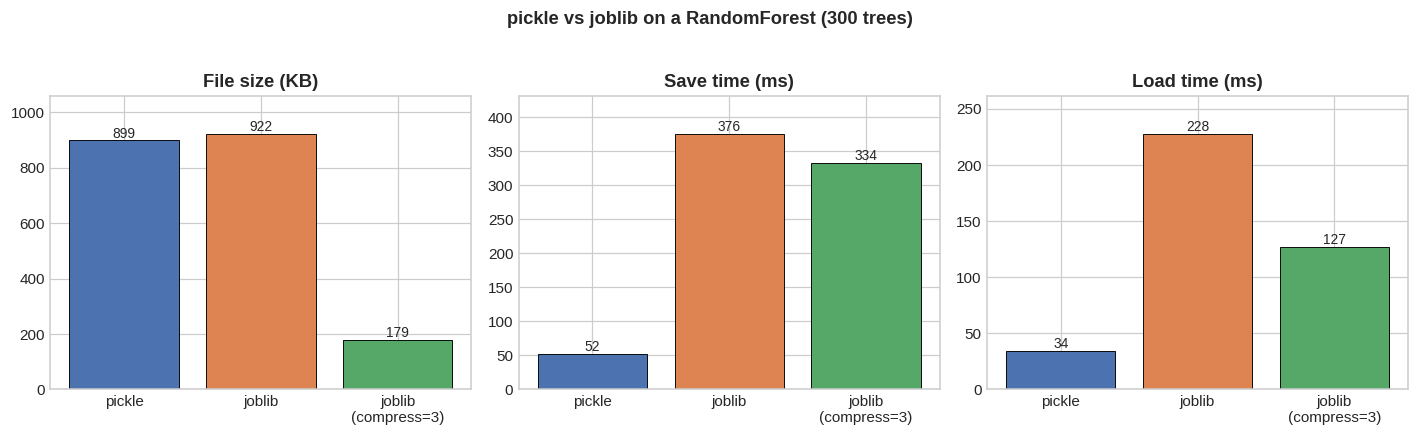

In [5]:
# Graph: size / save time / load time comparison
names = list(results.keys())
metrics = [("size", "File size (KB)"), ("save", "Save time (ms)"), ("load", "Load time (ms)")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (key, title) in zip(axes, metrics):
    vals = [results[n][key] for n in names]
    bars = ax.bar(names, vals, color=COLORS[:3], edgecolor="black", linewidth=0.6)
    ax.set_title(title)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
    ax.margins(y=0.15)
fig.suptitle("pickle vs joblib on a RandomForest (300 trees)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

In [26]:
# A minimal "deployment" function: load once, predict many times
def predict_from_disk(path, features):
    loaded = joblib.load(path)
    proba = loaded.predict_proba(features)[:, 1]
    return (proba > 0.5).astype(int), proba

labels, proba = predict_from_disk("saved_models/rf.joblib", X_test[:5])
print("Predictions:", labels, "\nP(benign):", proba.round(3), "\nTrue:", y_test[:5])

# Always save preprocessing + model together -> use a sklearn Pipeline in real projects

Predictions: [1 0 1 1 1] 
P(benign): [0.99  0.    0.663 0.893 0.73 ] 
True: [1 0 1 1 0]


**Best practices**
- Save the **whole pipeline** (scaler + model), not just the model, so inference sees the same preprocessing.
- Record library versions (`pip freeze`) and the training date/metrics next to the file.
- For simple models you can also store only parameters (weights) in `.npz` / JSON — safer than pickle.

---
# Part 2 — Perceptrons, Activation Functions, Forward & Backward Propagation

## 2.1 The Perceptron
A perceptron computes a weighted sum and applies a step function:

$$z = \mathbf{w}\cdot\mathbf{x} + b, \qquad \hat y = \begin{cases}1 & z \ge 0\\ 0 & z<0\end{cases}$$

Learning rule: for every sample, $\;\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y-\hat y)\,\mathbf{x}$, $\; b \leftarrow b + \eta\,(y-\hat y)$.

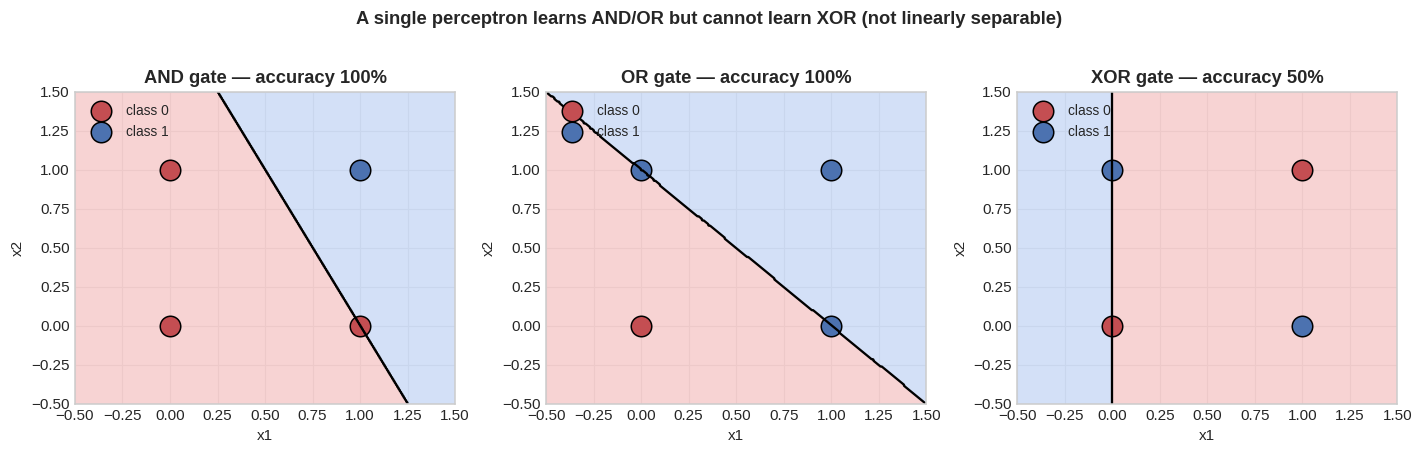

In [7]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=25):
        self.lr, self.epochs = lr, epochs
    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)
    def fit(self, X, y):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.errors = []
        for _ in range(self.epochs):
            err = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - self.predict(xi.reshape(1, -1))[0])
                self.w += update * xi; self.b += update
                err += int(update != 0)
            self.errors.append(err)
        return self

X_log = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": np.array([0, 0, 0, 1]), "OR": np.array([0, 1, 1, 1]), "XOR": np.array([0, 1, 1, 0])}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
for ax, (name, y) in zip(axes, gates.items()):
    p = Perceptron(lr=0.1, epochs=30).fit(X_log, y)
    Z = p.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=["#f6c9c9", "#c9d9f6"], alpha=0.8)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1.5)
    ax.scatter(X_log[y == 0, 0], X_log[y == 0, 1], s=180, c="#C44E52", edgecolor="k", label="class 0")
    ax.scatter(X_log[y == 1, 0], X_log[y == 1, 1], s=180, c="#4C72B0", edgecolor="k", label="class 1")
    acc = accuracy_score(y, p.predict(X_log))
    ax.set_title(f"{name} gate — accuracy {acc:.0%}")
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="upper left")
plt.suptitle("A single perceptron learns AND/OR but cannot learn XOR (not linearly separable)",
             fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

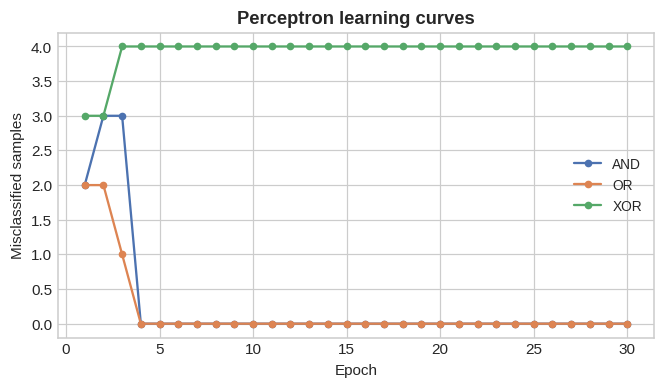

In [8]:
# Training convergence: number of misclassifications per epoch
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, y), c in zip(gates.items(), COLORS):
    ax.plot(range(1, 31), Perceptron(0.1, 30).fit(X_log, y).errors, marker="o", ms=4, color=c, label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Misclassified samples"); ax.set_title("Perceptron learning curves")
ax.legend(); plt.show()

**Takeaway:** XOR needs a **hidden layer** with a **non-linear activation** — the motivation for multi-layer neural networks.

## 2.2 Activation Functions
Without non-linear activations, stacked layers collapse into one linear layer. Common choices:

| Function | Formula | Used for |
|---|---|---|
| Sigmoid | $1/(1+e^{-z})$ | Binary output probability |
| Tanh | $\tanh z$ | Zero-centred hidden units |
| ReLU | $\max(0,z)$ | Default for hidden layers |
| Leaky ReLU | $\max(\alpha z, z)$ | Avoids "dying ReLU" |

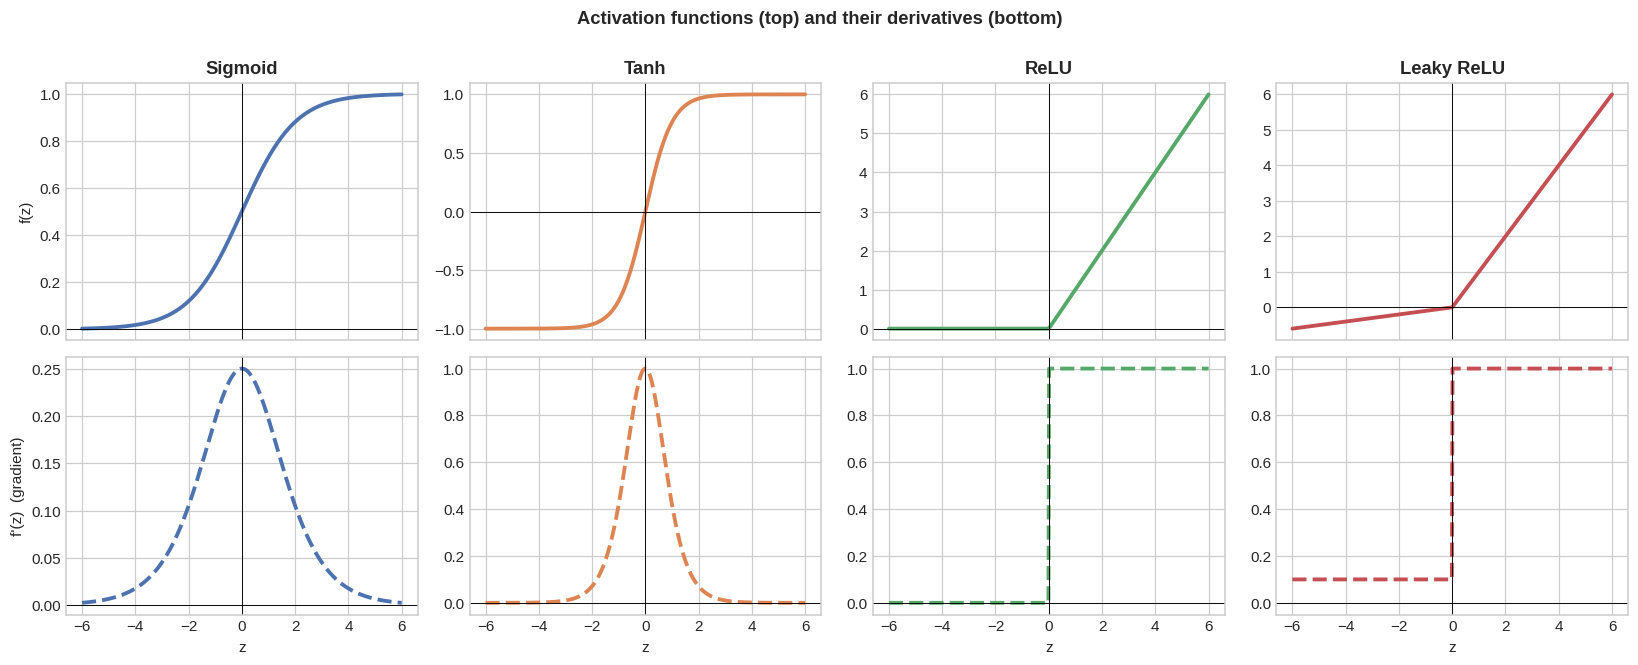

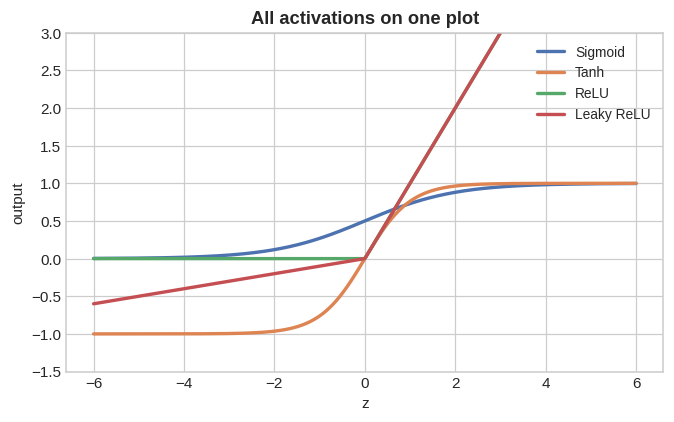

In [9]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
def relu(z): return np.maximum(0, z)
def leaky_relu(z, a=0.1): return np.where(z > 0, z, a * z)

z = np.linspace(-6, 6, 500)
acts = {
    "Sigmoid":    (sigmoid(z),    sigmoid(z) * (1 - sigmoid(z))),
    "Tanh":       (np.tanh(z),    1 - np.tanh(z) ** 2),
    "ReLU":       (relu(z),       (z > 0).astype(float)),
    "Leaky ReLU": (leaky_relu(z), np.where(z > 0, 1.0, 0.1)),
}
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for j, (name, (f, df)) in enumerate(acts.items()):
    axes[0, j].plot(z, f, color=COLORS[j], lw=2.5); axes[0, j].set_title(name)
    axes[1, j].plot(z, df, color=COLORS[j], lw=2.5, ls="--"); axes[1, j].set_xlabel("z")
    for r in range(2):
        axes[r, j].axhline(0, c="k", lw=0.6); axes[r, j].axvline(0, c="k", lw=0.6)
axes[0, 0].set_ylabel("f(z)"); axes[1, 0].set_ylabel("f'(z)  (gradient)")
plt.suptitle("Activation functions (top) and their derivatives (bottom)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# Overlay for easy comparison
fig, ax = plt.subplots(figsize=(7, 4))
for (name, (f, _)), c in zip(acts.items(), COLORS):
    ax.plot(z, f, lw=2.2, color=c, label=name)
ax.set_ylim(-1.5, 3); ax.set_xlabel("z"); ax.set_ylabel("output"); ax.legend()
ax.set_title("All activations on one plot"); plt.show()

> **Observation:** Sigmoid/Tanh gradients are ≈ 0 for large $|z|$ (**vanishing gradient**); sigmoid's max gradient is only 0.25.
> ReLU keeps a gradient of 1 for $z>0$, which is why it trains deep networks faster.

## 2.3 Forward & Backward Propagation (worked example)
Network: 2 inputs → 2 hidden (sigmoid) → 1 output (sigmoid), loss = binary cross-entropy.

**Forward:** $z^{[1]}=W^{[1]}x+b^{[1]},\; a^{[1]}=\sigma(z^{[1]}),\; z^{[2]}=W^{[2]}a^{[1]}+b^{[2]},\; \hat y=\sigma(z^{[2]})$

**Backward (chain rule):**
$$\delta^{[2]} = \hat y - y,\quad \frac{\partial L}{\partial W^{[2]}}=\delta^{[2]}a^{[1]T},\quad
\delta^{[1]}=(W^{[2]T}\delta^{[2]})\odot a^{[1]}(1-a^{[1]}),\quad \frac{\partial L}{\partial W^{[1]}}=\delta^{[1]}x^T$$

In [10]:
# Tiny network with fixed numbers so we can follow every step
x  = np.array([[1.0], [2.0]]);  y = 1.0
W1 = np.array([[0.1, 0.4], [-0.3, 0.2]]); b1 = np.array([[0.0], [0.1]])
W2 = np.array([[0.5, -0.6]]);              b2 = np.array([[0.05]])

def forward(W1, b1, W2, b2):
    z1 = W1 @ x + b1; a1 = sigmoid(z1)
    z2 = W2 @ a1 + b2; a2 = sigmoid(z2)
    loss = -(y * np.log(a2) + (1 - y) * np.log(1 - a2))
    return z1, a1, z2, a2, loss.item()

z1, a1, z2, a2, L = forward(W1, b1, W2, b2)
print("FORWARD  z1 =", z1.ravel().round(4), " a1 =", a1.ravel().round(4))
print("         z2 =", z2.ravel().round(4), " y_hat =", a2.ravel().round(4), " loss =", round(L, 4))

# Backward pass (manual chain rule)
d2  = a2 - y                       # (1,1)
dW2 = d2 @ a1.T;  db2 = d2
d1  = (W2.T @ d2) * a1 * (1 - a1)  # (2,1)
dW1 = d1 @ x.T;   db1 = d1

# Verify with numerical gradients (finite differences)
def numeric_grad(param_idx, eps=1e-6):
    params = [W1.copy(), b1.copy(), W2.copy(), b2.copy()]
    g = np.zeros_like(params[param_idx])
    for i in np.ndindex(g.shape):
        params[param_idx][i] += eps;  lp = forward(*params)[-1]
        params[param_idx][i] -= 2 * eps; lm = forward(*params)[-1]
        params[param_idx][i] += eps
        g[i] = (lp - lm) / (2 * eps)
    return g

analytic = [dW1, db1, dW2, db2]
numeric  = [numeric_grad(i) for i in range(4)]
print("\nMax |analytic - numeric| per parameter:",
      [f"{np.max(np.abs(a - n)):.1e}" for a, n in zip(analytic, numeric)])

FORWARD  z1 = [0.9 0.2]  a1 = [0.7109 0.5498]
         z2 = [0.0756]  y_hat = [0.5189]  loss = 0.6561

Max |analytic - numeric| per parameter: ['7.2e-11', '7.2e-11', '1.5e-10', '1.7e-11']


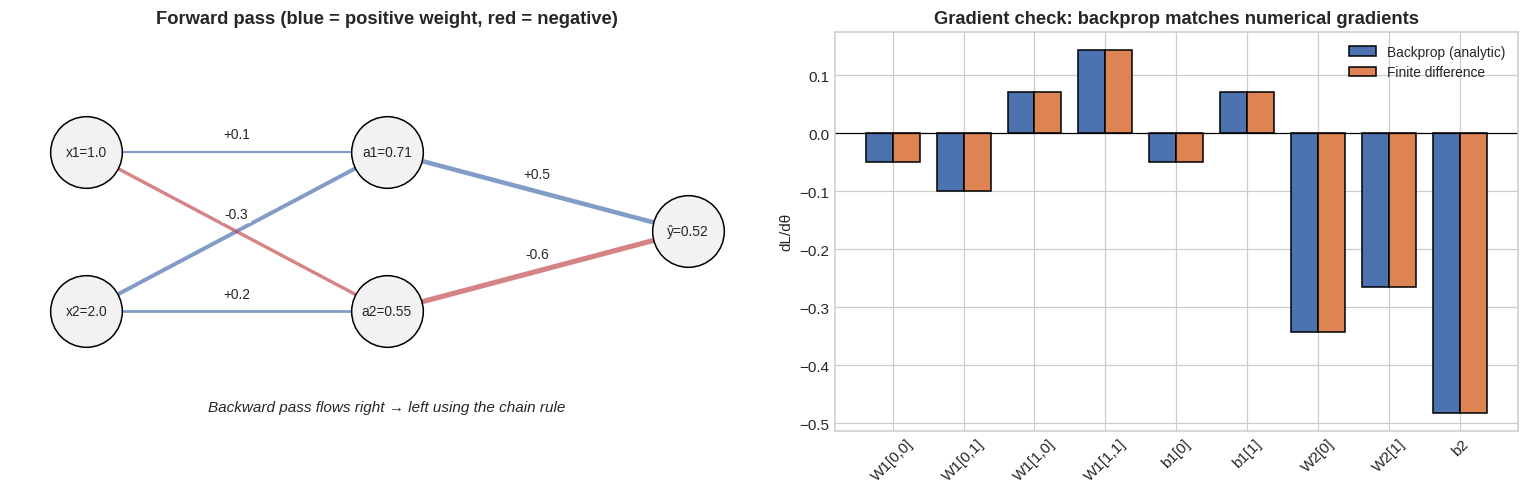

In [11]:
# Graph: backprop gradients vs numerical gradients  +  network diagram with values
labels = ["W1[0,0]", "W1[0,1]", "W1[1,0]", "W1[1,1]", "b1[0]", "b1[1]", "W2[0]", "W2[1]", "b2"]
a_flat = np.concatenate([g.ravel() for g in analytic]); n_flat = np.concatenate([g.ravel() for g in numeric])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
# --- network diagram
ax = axes[0]; ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
pos = {"x1": (1, 4.2), "x2": (1, 1.8), "h1": (5, 4.2), "h2": (5, 1.8), "o": (9, 3)}
for (a, b, w) in [("x1", "h1", W1[0, 0]), ("x2", "h1", W1[0, 1]), ("x1", "h2", W1[1, 0]),
                  ("x2", "h2", W1[1, 1]), ("h1", "o", W2[0, 0]), ("h2", "o", W2[0, 1])]:
    (x0, y0), (x1_, y1) = pos[a], pos[b]
    ax.plot([x0, x1_], [y0, y1], color="#4C72B0" if w > 0 else "#C44E52", lw=1 + 4 * abs(w), alpha=0.7, zorder=1)
    ax.text((x0 + x1_) / 2, (y0 + y1) / 2 + 0.2, f"{w:+.1f}", fontsize=9, ha="center",
            bbox=dict(fc="white", ec="none", pad=1))
vals = {"x1": f"x1={x[0,0]:.1f}", "x2": f"x2={x[1,0]:.1f}", "h1": f"a1={a1[0,0]:.2f}",
        "h2": f"a2={a1[1,0]:.2f}", "o": f"ŷ={a2[0,0]:.2f}"}
for k, (px, py) in pos.items():
    ax.scatter(px, py, s=2200, c="#f2f2f2", edgecolor="k", zorder=2); ax.text(px, py, vals[k], ha="center", va="center", fontsize=9, zorder=3)
ax.set_title("Forward pass (blue = positive weight, red = negative)")
ax.text(5, 0.3, "Backward pass flows right → left using the chain rule", ha="center", style="italic")
# --- gradient comparison
ax = axes[1]; idx = np.arange(len(labels)); w = 0.38
ax.bar(idx - w / 2, a_flat, w, label="Backprop (analytic)", color=COLORS[0], edgecolor="k")
ax.bar(idx + w / 2, n_flat, w, label="Finite difference", color=COLORS[1], edgecolor="k")
ax.set_xticks(idx); ax.set_xticklabels(labels, rotation=45); ax.axhline(0, c="k", lw=0.8)
ax.set_ylabel("dL/dθ"); ax.set_title("Gradient check: backprop matches numerical gradients"); ax.legend()
plt.tight_layout(); plt.show()

---
# Part 3 — Loss Functions and Optimizers

## 3.1 Loss functions
The loss measures *how wrong* predictions are; training = minimizing it.

| Loss | Formula | Task |
|---|---|---|
| MSE | $\frac1m\sum(y-\hat y)^2$ | Regression |
| MAE | $\frac1m\sum|y-\hat y|$ | Regression, robust to outliers |
| Huber | quadratic near 0, linear far | Regression, robust + smooth |
| Binary cross-entropy | $-\frac1m\sum[y\log\hat y+(1-y)\log(1-\hat y)]$ | Binary classification |
| Categorical cross-entropy | $-\sum y_k\log\hat y_k$ | Multi-class |

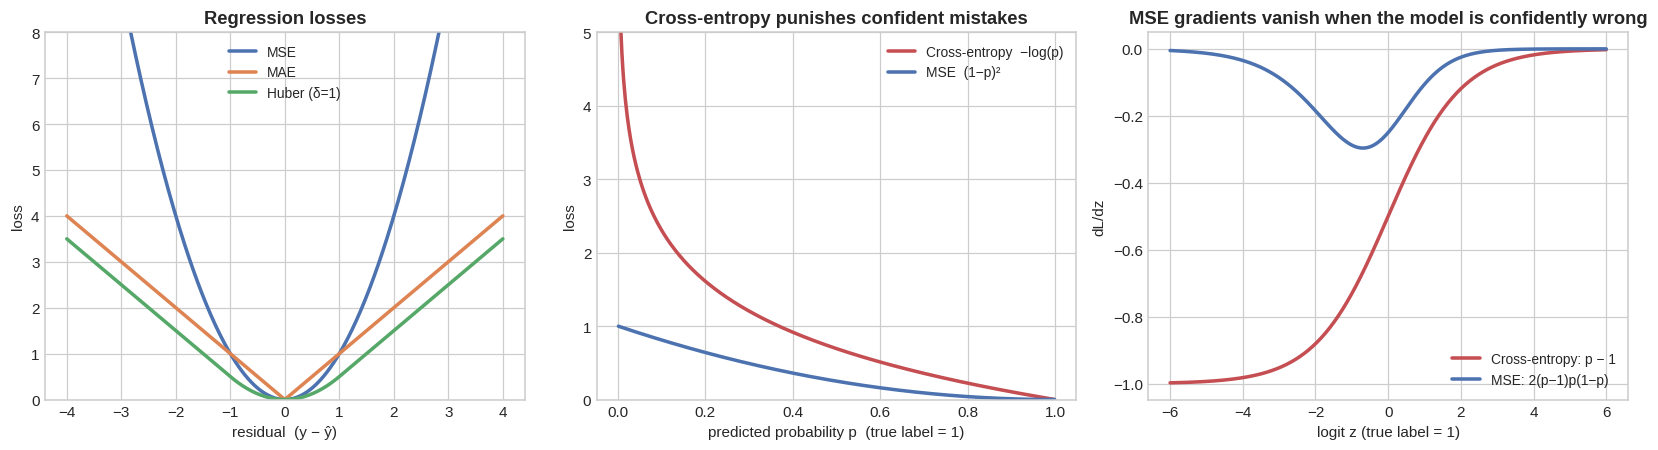

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) Regression losses vs residual
r = np.linspace(-4, 4, 400)
huber = np.where(np.abs(r) <= 1, 0.5 * r ** 2, np.abs(r) - 0.5)
axes[0].plot(r, r ** 2, label="MSE", color=COLORS[0], lw=2.3)
axes[0].plot(r, np.abs(r), label="MAE", color=COLORS[1], lw=2.3)
axes[0].plot(r, huber, label="Huber (δ=1)", color=COLORS[2], lw=2.3)
axes[0].set_ylim(0, 8); axes[0].set_xlabel("residual  (y − ŷ)"); axes[0].set_ylabel("loss")
axes[0].set_title("Regression losses"); axes[0].legend()

# (b) Classification losses when true label y = 1
p = np.linspace(0.001, 0.999, 500)
axes[1].plot(p, -np.log(p), label="Cross-entropy  −log(p)", color=COLORS[3], lw=2.3)
axes[1].plot(p, (1 - p) ** 2, label="MSE  (1−p)²", color=COLORS[0], lw=2.3)
axes[1].set_ylim(0, 5); axes[1].set_xlabel("predicted probability p  (true label = 1)")
axes[1].set_ylabel("loss"); axes[1].set_title("Cross-entropy punishes confident mistakes"); axes[1].legend()

# (c) Gradient w.r.t. logit z for y=1  (p = sigmoid(z))
zz = np.linspace(-6, 6, 400); pp = sigmoid(zz)
axes[2].plot(zz, pp - 1, label="Cross-entropy: p − 1", color=COLORS[3], lw=2.3)
axes[2].plot(zz, 2 * (pp - 1) * pp * (1 - pp), label="MSE: 2(p−1)p(1−p)", color=COLORS[0], lw=2.3)
axes[2].set_xlabel("logit z (true label = 1)"); axes[2].set_ylabel("dL/dz")
axes[2].set_title("MSE gradients vanish when the model is confidently wrong"); axes[2].legend()
plt.tight_layout(); plt.show()

In [13]:
# Implementations used later in our network
def mse(y_true, y_pred):  return np.mean((y_true - y_pred) ** 2)
def bce(y_true, y_pred, eps=1e-12):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

y_t = np.array([1, 0, 1, 1]); good = np.array([.9, .1, .8, .95]); bad = np.array([.2, .9, .3, .1])
print(f"Good predictions -> MSE={mse(y_t, good):.3f}  BCE={bce(y_t, good):.3f}")
print(f"Bad  predictions -> MSE={mse(y_t, bad):.3f}  BCE={bce(y_t, bad):.3f}")

Good predictions -> MSE=0.016  BCE=0.121
Bad  predictions -> MSE=0.688  BCE=1.855


## 3.2 Optimizers

Gradient descent updates parameters $\theta$ opposite to the gradient of the loss.

- **SGD:** $\theta \leftarrow \theta - \eta\, g$  (on a mini-batch)
- **SGD + Momentum:** $v \leftarrow \beta v + g,\;\; \theta\leftarrow\theta-\eta v$ — smooths oscillations
- **Adam:** keeps running averages of the gradient (1st moment $m$) and squared gradient (2nd moment $v$):

$$m\leftarrow\beta_1 m+(1-\beta_1)g,\quad v\leftarrow\beta_2 v+(1-\beta_2)g^2,\quad
\hat m=\frac{m}{1-\beta_1^t},\ \hat v=\frac{v}{1-\beta_2^t},\quad \theta\leftarrow\theta-\eta\frac{\hat m}{\sqrt{\hat v}+\epsilon}$$

Adam gives each parameter its own adaptive step size.

In [14]:
class SGD:
    def __init__(self, lr=0.01): self.lr = lr
    def step(self, params, grads):
        for p, g in zip(params, grads): p -= self.lr * g

class Momentum:
    def __init__(self, lr=0.01, beta=0.9): self.lr, self.beta, self.v = lr, beta, None
    def step(self, params, grads):
        if self.v is None: self.v = [np.zeros_like(p) for p in params]
        for p, g, v in zip(params, grads, self.v):
            v *= self.beta; v += g; p -= self.lr * v

class Adam:
    def __init__(self, lr=0.001, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t, self.m, self.v = lr, b1, b2, eps, 0, None, None
    def step(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]
        self.t += 1
        for p, g, m, v in zip(params, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g ** 2
            m_hat = m / (1 - self.b1 ** self.t); v_hat = v / (1 - self.b2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

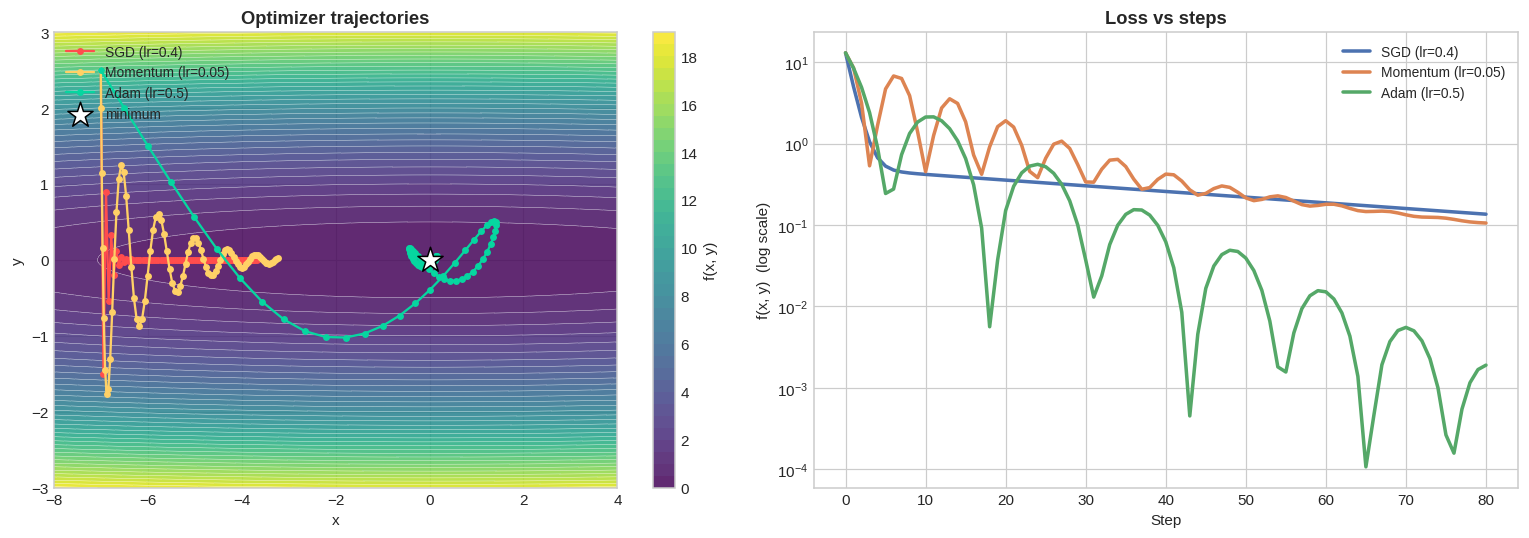

In [15]:
# Visual comparison on an elongated bowl f(x,y) = 0.01x² + 2y²  (steep in y, flat in x)
f  = lambda x, y: 0.01 * x ** 2 + 2 * y ** 2
df = lambda p: np.array([0.02 * p[0], 4 * p[1]])

def run(opt, start=(-7.0, 2.5), steps=80):
    p = np.array(start, dtype=float); path = [p.copy()]
    for _ in range(steps):
        opt.step([p], [df(p)]); path.append(p.copy())
    return np.array(path)

paths = {"SGD (lr=0.4)": run(SGD(0.4)),
         "Momentum (lr=0.05)": run(Momentum(0.05, 0.9)),
         "Adam (lr=0.5)": run(Adam(0.5))}

gx, gy = np.meshgrid(np.linspace(-8, 4, 300), np.linspace(-3, 3, 300))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
cs = ax.contourf(gx, gy, f(gx, gy), levels=40, cmap="viridis", alpha=0.85)
ax.contour(gx, gy, f(gx, gy), levels=40, colors="white", linewidths=0.3)
for (name, path), c in zip(paths.items(), ["#ff4d4d", "#ffd166", "#06d6a0"]):
    ax.plot(path[:, 0], path[:, 1], "o-", color=c, ms=3.5, lw=1.5, label=name)
ax.scatter(0, 0, marker="*", s=300, c="white", edgecolor="k", zorder=5, label="minimum")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("Optimizer trajectories"); ax.legend(loc="upper left")
plt.colorbar(cs, ax=ax, label="f(x, y)")

ax = axes[1]
for (name, path), c in zip(paths.items(), COLORS):
    ax.plot(f(path[:, 0], path[:, 1]), lw=2.3, color=c, label=name)
ax.set_yscale("log"); ax.set_xlabel("Step"); ax.set_ylabel("f(x, y)  (log scale)")
ax.set_title("Loss vs steps"); ax.legend()
plt.tight_layout(); plt.show()

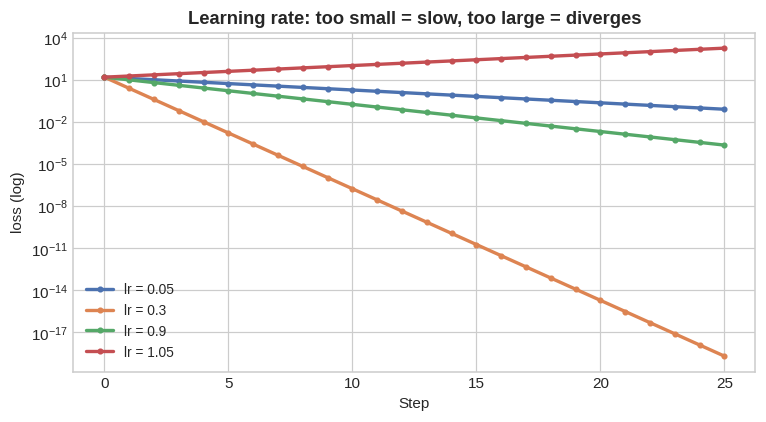

In [16]:
# Effect of the learning rate for plain SGD on f(x) = x²
fig, ax = plt.subplots(figsize=(8, 4))
for lr, c in zip([0.05, 0.3, 0.9, 1.05], COLORS):
    x = 4.0; hist = [x ** 2]
    for _ in range(25):
        x -= lr * 2 * x; hist.append(x ** 2)
    ax.plot(hist, lw=2.2, color=c, marker="o", ms=3, label=f"lr = {lr}")
ax.set_yscale("log"); ax.set_xlabel("Step"); ax.set_ylabel("loss (log)")
ax.set_title("Learning rate: too small = slow, too large = diverges"); ax.legend(); plt.show()

---
# Part 4 — Neural Network from Scratch (NumPy)

We build a fully-connected network with:
- **ReLU** hidden layers (He initialization) and a **sigmoid** output
- **Binary cross-entropy** loss
- **Backpropagation** implemented by hand
- Pluggable **optimizers** (SGD / Momentum / Adam) and mini-batch training

Dataset: `make_moons` — two interleaving half-circles (not linearly separable).

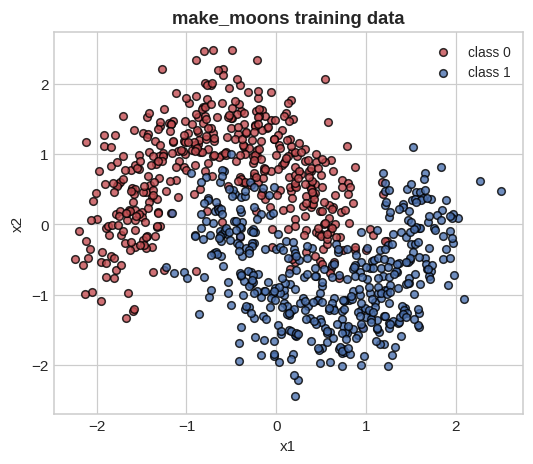

In [17]:
X, y = make_moons(n_samples=1200, noise=0.25, random_state=1)
X = StandardScaler().fit_transform(X); y = y.reshape(-1, 1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(*X_tr[y_tr.ravel() == 0].T, c=COLORS[3], edgecolor="k", s=25, alpha=.8, label="class 0")
ax.scatter(*X_tr[y_tr.ravel() == 1].T, c=COLORS[0], edgecolor="k", s=25, alpha=.8, label="class 1")
ax.set_title("make_moons training data"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); plt.show()

In [18]:
class NeuralNetwork:
    # Fully-connected network: ReLU hidden layers, sigmoid output, BCE loss.

    def __init__(self, layer_sizes, seed=42):
        rng = np.random.default_rng(seed)
        self.sizes = layer_sizes
        self.W = [rng.normal(0, np.sqrt(2 / layer_sizes[i]), (layer_sizes[i], layer_sizes[i + 1]))
                  for i in range(len(layer_sizes) - 1)]                       # He init
        self.b = [np.zeros((1, layer_sizes[i + 1])) for i in range(len(layer_sizes) - 1)]
        self.history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}

    # ---------- forward propagation
    def forward(self, X):
        self.A, self.Z = [X], []
        L = len(self.W)
        for i in range(L):
            Z = self.A[-1] @ self.W[i] + self.b[i]
            self.Z.append(Z)
            self.A.append(relu(Z) if i < L - 1 else sigmoid(Z))
        return self.A[-1]

    # ---------- loss
    @staticmethod
    def loss(y_pred, y_true): return bce(y_true, y_pred)

    # ---------- backward propagation
    def backward(self, y_true):
        m = y_true.shape[0]; L = len(self.W)
        dW, db = [None] * L, [None] * L
        dZ = self.A[-1] - y_true                       # sigmoid + BCE  ->  ŷ − y
        for i in reversed(range(L)):
            dW[i] = self.A[i].T @ dZ / m
            db[i] = dZ.sum(axis=0, keepdims=True) / m
            if i > 0:
                dZ = (dZ @ self.W[i].T) * (self.Z[i - 1] > 0)      # ReLU derivative
        return dW, db

    # ---------- training loop
    def fit(self, X, y, optimizer, epochs=200, batch_size=64, X_val=None, y_val=None, seed=0, verbose=0):
        rng = np.random.default_rng(seed)
        for ep in range(1, epochs + 1):
            idx = rng.permutation(len(X))
            for s in range(0, len(X), batch_size):
                b = idx[s:s + batch_size]
                self.forward(X[b])
                dW, db = self.backward(y[b])
                optimizer.step(self.W + self.b, dW + db)           # in-place weight update
            p = self.forward(X);  self.history["loss"].append(self.loss(p, y))
            self.history["acc"].append(np.mean((p > .5) == y))
            if X_val is not None:
                pv = self.forward(X_val); self.history["val_loss"].append(self.loss(pv, y_val))
                self.history["val_acc"].append(np.mean((pv > .5) == y_val))
            if verbose and ep % verbose == 0:
                print(f"epoch {ep:4d}  loss={self.history['loss'][-1]:.4f}  acc={self.history['acc'][-1]:.3f}")
        return self

    def predict_proba(self, X): return self.forward(X)
    def predict(self, X): return (self.forward(X) > 0.5).astype(int)

In [19]:
# Gradient check: is our hand-written backprop correct?
def grad_check(seed=0, eps=1e-5):
    rng = np.random.default_rng(seed)
    net = NeuralNetwork([2, 5, 4, 1], seed=seed)
    Xs, ys = rng.normal(size=(8, 2)), rng.integers(0, 2, (8, 1))
    net.forward(Xs); dW, _ = net.backward(ys)
    diffs = []
    for l in range(len(net.W)):
        for i in np.ndindex(net.W[l].shape):
            old = net.W[l][i]
            net.W[l][i] = old + eps; lp = net.loss(net.forward(Xs), ys)
            net.W[l][i] = old - eps; lm = net.loss(net.forward(Xs), ys)
            net.W[l][i] = old
            diffs.append(abs((lp - lm) / (2 * eps) - dW[l][i]))
    return np.array(diffs)

d = grad_check()
print(f"Max gradient error over {len(d)} weights: {d.max():.2e}  ->  backprop is correct" if d.max() < 1e-6 else "Mismatch!")

Max gradient error over 34 weights: 7.23e-12  ->  backprop is correct


In [20]:
# Train with SGD, Momentum and Adam (same init, same data, same epochs)
configs = {"SGD (lr=0.05)": SGD(0.05), "Momentum (lr=0.05)": Momentum(0.05, 0.9), "Adam (lr=0.01)": Adam(0.01)}
nets = {}
for name, opt in configs.items():
    nets[name] = NeuralNetwork([2, 16, 16, 1], seed=7).fit(X_tr, y_tr, opt, epochs=150, batch_size=64,
                                                          X_val=X_te, y_val=y_te)
    print(f"{name:<20} train acc={nets[name].history['acc'][-1]:.3f}   test acc={nets[name].history['val_acc'][-1]:.3f}")

SGD (lr=0.05)        train acc=0.947   test acc=0.957
Momentum (lr=0.05)   train acc=0.947   test acc=0.960
Adam (lr=0.01)       train acc=0.948   test acc=0.960


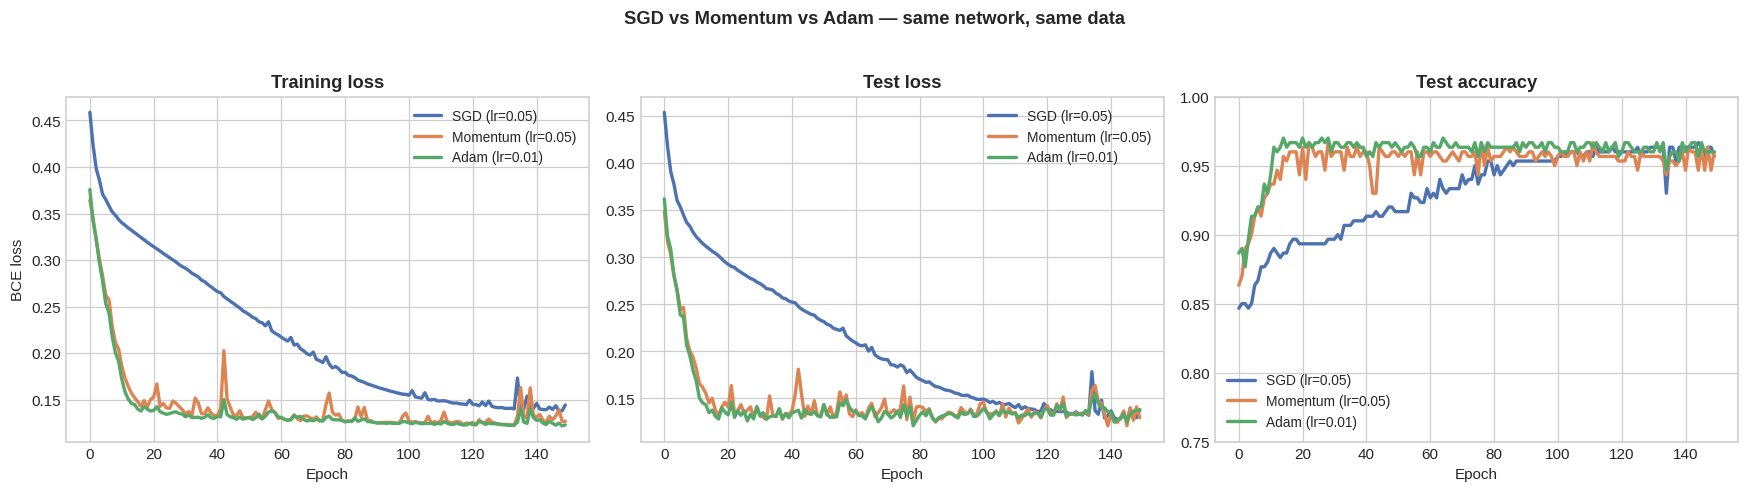

In [21]:
# Graph: optimizer comparison on the real network
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for (name, net), c in zip(nets.items(), COLORS):
    axes[0].plot(net.history["loss"], lw=2.2, color=c, label=name)
    axes[1].plot(net.history["val_loss"], lw=2.2, color=c, label=name)
    axes[2].plot(net.history["val_acc"], lw=2.2, color=c, label=name)
axes[0].set_title("Training loss"); axes[1].set_title("Test loss"); axes[2].set_title("Test accuracy")
for a in axes: a.set_xlabel("Epoch"); a.legend()
axes[0].set_ylabel("BCE loss"); axes[2].set_ylim(0.75, 1.0)
plt.suptitle("SGD vs Momentum vs Adam — same network, same data", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

epoch  100  loss=0.1260  acc=0.944
epoch  200  loss=0.1270  acc=0.944
epoch  300  loss=0.1126  acc=0.949

Final test accuracy: 0.9567


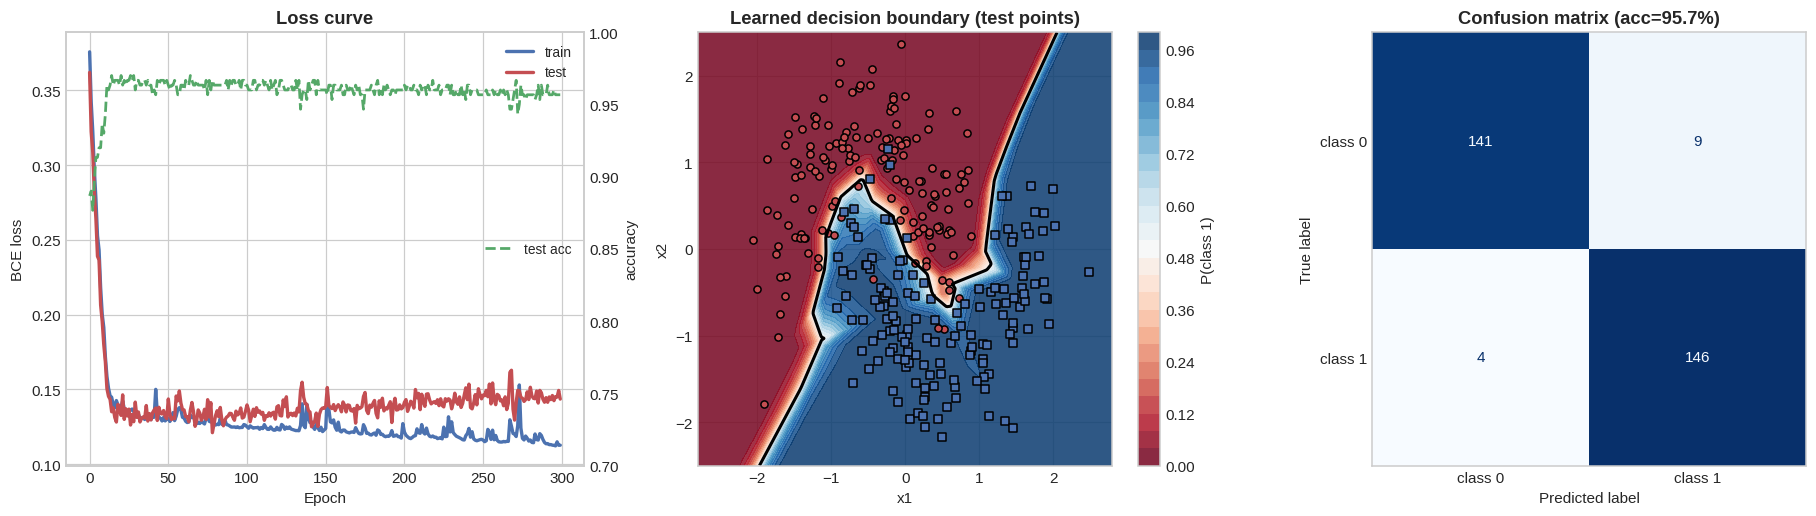

In [22]:
# Final model: train longer with Adam and visualise everything
net = NeuralNetwork([2, 16, 16, 1], seed=7).fit(X_tr, y_tr, Adam(0.01), epochs=300, batch_size=64,
                                               X_val=X_te, y_val=y_te, verbose=100)
test_acc = accuracy_score(y_te, net.predict(X_te))
print(f"\nFinal test accuracy: {test_acc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
# (1) loss curve
ax = axes[0]
ax.plot(net.history["loss"], color=COLORS[0], lw=2.2, label="train")
ax.plot(net.history["val_loss"], color=COLORS[3], lw=2.2, label="test")
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE loss"); ax.set_title("Loss curve"); ax.legend()
ax2 = ax.twinx(); ax2.plot(net.history["val_acc"], color=COLORS[2], lw=1.8, ls="--", label="test acc")
ax2.set_ylabel("accuracy"); ax2.set_ylim(0.7, 1.0); ax2.grid(False); ax2.legend(loc="center right")

# (2) decision boundary
ax = axes[1]
gx, gy = np.meshgrid(np.linspace(-2.8, 2.8, 400), np.linspace(-2.5, 2.5, 400))
P = net.predict_proba(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
cs = ax.contourf(gx, gy, P, levels=25, cmap="RdBu", alpha=0.85)
ax.contour(gx, gy, P, levels=[0.5], colors="k", linewidths=2)
ax.scatter(*X_te[y_te.ravel() == 0].T, c=COLORS[3], edgecolor="k", s=22, marker="o")
ax.scatter(*X_te[y_te.ravel() == 1].T, c=COLORS[0], edgecolor="k", s=22, marker="s")
plt.colorbar(cs, ax=ax, label="P(class 1)"); ax.set_title("Learned decision boundary (test points)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")

# (3) confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_te, net.predict(X_te)), display_labels=["class 0", "class 1"]).plot(
    ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title(f"Confusion matrix (acc={test_acc:.1%})"); axes[2].grid(False)
plt.tight_layout(); plt.show()

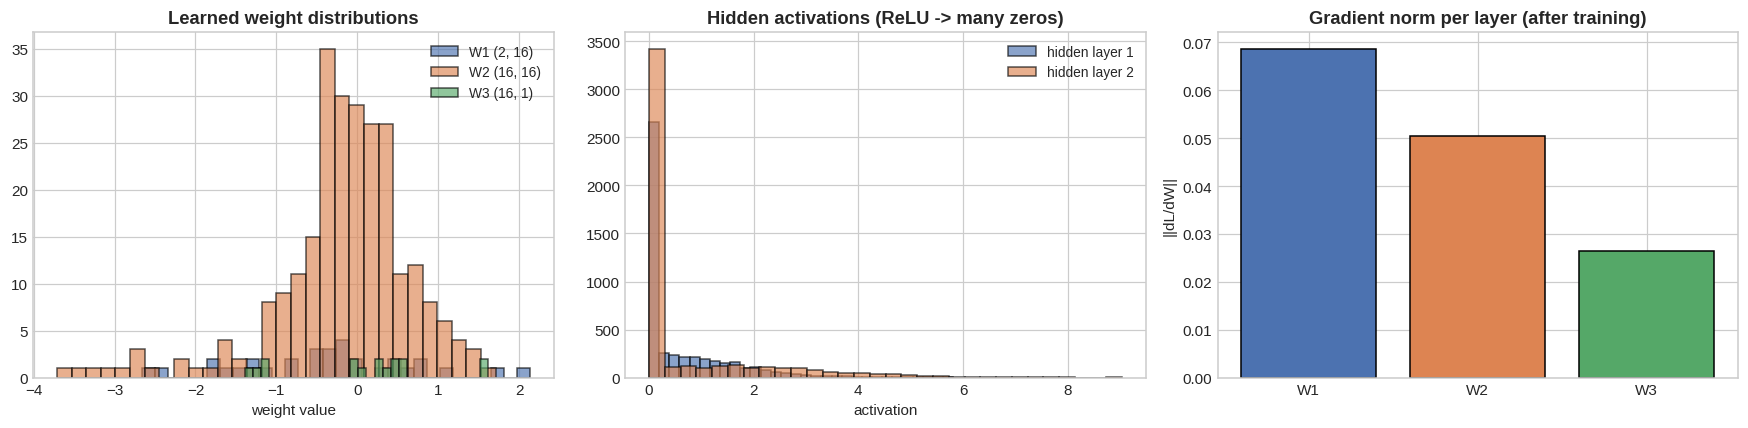

In [23]:
# Look inside: weight distributions, hidden-layer activations and a gradient-norm check per layer
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, W in enumerate(net.W):
    axes[0].hist(W.ravel(), bins=30, alpha=.65, label=f"W{i+1} {W.shape}", color=COLORS[i], edgecolor="k")
axes[0].set_title("Learned weight distributions"); axes[0].set_xlabel("weight value"); axes[0].legend()

net.forward(X_te)
for i, c in zip([1, 2], COLORS):
    axes[1].hist(net.A[i].ravel(), bins=30, alpha=.65, color=c, edgecolor="k", label=f"hidden layer {i}")
axes[1].set_title("Hidden activations (ReLU -> many zeros)"); axes[1].set_xlabel("activation"); axes[1].legend()

net.forward(X_tr[:256]); dW, _ = net.backward(y_tr[:256])
axes[2].bar([f"W{i+1}" for i in range(len(dW))], [np.linalg.norm(g) for g in dW],
            color=COLORS[:3], edgecolor="k")
axes[2].set_title("Gradient norm per layer (after training)"); axes[2].set_ylabel("||dL/dW||")
plt.tight_layout(); plt.show()

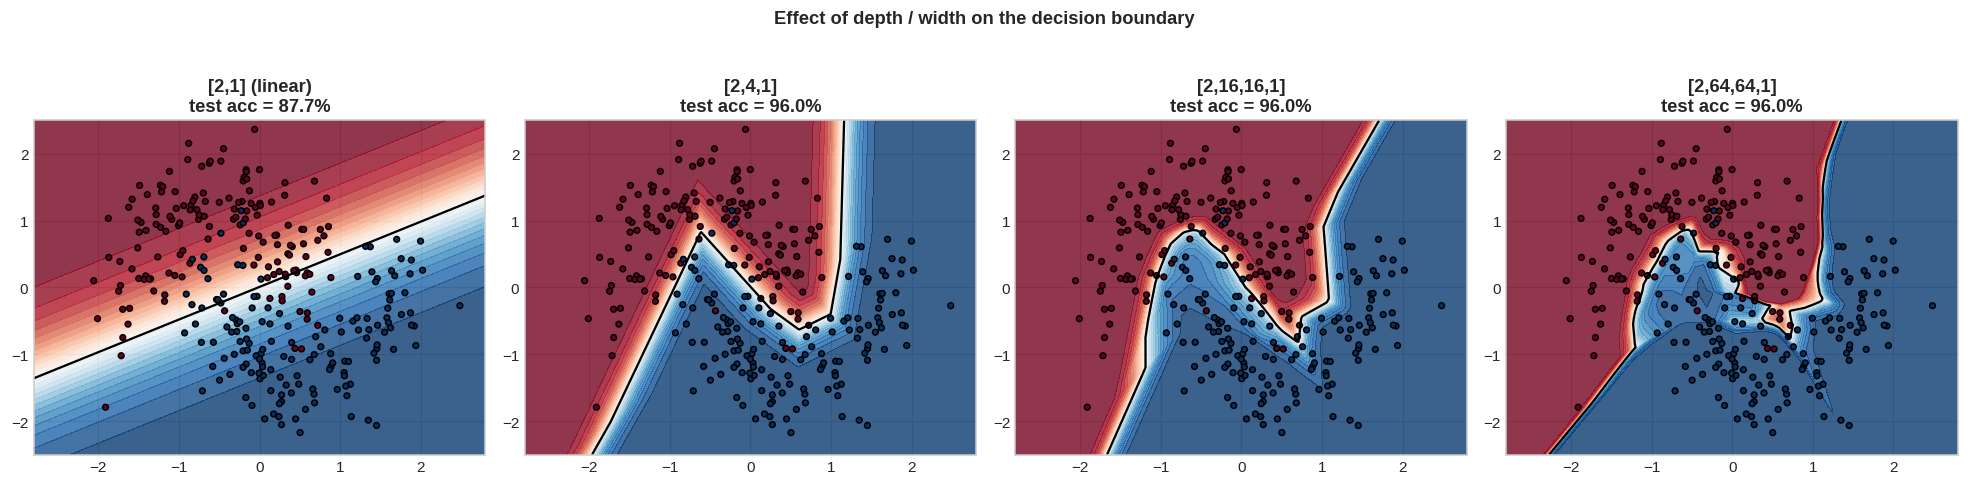

In [24]:
# How network capacity changes the decision boundary (underfit -> good fit)
archs = {"[2,1] (linear)": [2, 1], "[2,4,1]": [2, 4, 1], "[2,16,16,1]": [2, 16, 16, 1], "[2,64,64,1]": [2, 64, 64, 1]}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, arch) in zip(axes, archs.items()):
    m = NeuralNetwork(arch, seed=3).fit(X_tr, y_tr, Adam(0.01), epochs=200, batch_size=64)
    P = m.predict_proba(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, P, levels=25, cmap="RdBu", alpha=.8); ax.contour(gx, gy, P, levels=[.5], colors="k")
    ax.scatter(*X_te.T, c=y_te.ravel(), cmap="RdBu", edgecolor="k", s=14)
    ax.set_title(f"{name}\ntest acc = {accuracy_score(y_te, m.predict(X_te)):.1%}")
plt.suptitle("Effect of depth / width on the decision boundary", fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()

## 4.1 Saving & loading the from-scratch network (deployment, again!)
Option A — pickle the whole object. Option B — save only the **weights** with `joblib`/`np.savez` (more portable and safer).

In [25]:
# A) pickle the entire object
with open("saved_models/scratch_nn.pkl", "wb") as f: pickle.dump(net, f)
with open("saved_models/scratch_nn.pkl", "rb") as f: net_loaded = pickle.load(f)

# B) save only the parameters with joblib, rebuild the network from them
joblib.dump({"sizes": net.sizes, "W": net.W, "b": net.b}, "saved_models/scratch_weights.joblib")
state = joblib.load("saved_models/scratch_weights.joblib")
net_rebuilt = NeuralNetwork(state["sizes"]); net_rebuilt.W, net_rebuilt.b = state["W"], state["b"]

print("pickle  -> identical predictions:", np.array_equal(net.predict(X_te), net_loaded.predict(X_te)))
print("joblib  -> identical predictions:", np.array_equal(net.predict(X_te), net_rebuilt.predict(X_te)))
for p in ["scratch_nn.pkl", "scratch_weights.joblib"]:
    print(f"{p:<26} {os.path.getsize('saved_models/' + p) / 1024:.1f} KB")

pickle  -> identical predictions: True
joblib  -> identical predictions: True
scratch_nn.pkl             161.6 KB
scratch_weights.joblib     3.1 KB


---
# Summary

| Concept | Key idea |
|---|---|
| **pickle / joblib** | Serialize trained models; joblib is better for big NumPy arrays; never load untrusted files |
| **Perceptron** | Linear classifier; cannot solve XOR |
| **Activations** | Add non-linearity; ReLU for hidden layers, sigmoid/softmax at the output |
| **Forward prop** | Compute layer outputs → prediction → loss |
| **Backward prop** | Chain rule gives gradients layer by layer (verified with gradient check) |
| **Loss** | MSE/MAE for regression, cross-entropy for classification |
| **SGD** | Step against the gradient; sensitive to learning rate |
| **Adam** | Momentum + per-parameter adaptive step; usually converges fastest with little tuning |

### Practice exercises
1. Change the hidden activation to `tanh` and compare training curves.
2. Add L2 regularization to the loss and to the gradients; see how the decision boundary changes.
3. Implement RMSProp as another optimizer class and add it to the comparison.
4. Extend the network to multi-class classification using softmax + categorical cross-entropy.
5. Wrap scaler + model into a `Pipeline`, save it with joblib and serve it using a small Flask/FastAPI endpoint.